# Querying DataFrames with DuckDB

**DuckDB** (M07 L08) can query pandas and Polars DataFrames and Parquet files **in place** with SQL, without copying them into a database. You can mix SQL and DataFrame code freely and use whichever is clearer for each step.

**After this lesson you can:**

1. Query pandas and Polars DataFrames by their variable name.
2. Query Parquet files directly, including several files and glob patterns.
3. Move results back to pandas, Polars or Arrow.
4. Use the Python relational API and decide between SQL, pandas and Polars.

**Data:** NYC yellow taxi trips, January and February 2024, and the taxi zone lookup table.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

import polars as pl

JAN, FEB = datasets.taxi("2024-01"), datasets.taxi("2024-02")
zones_pl = pl.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

def show_plan(text: str) -> None:
    """Print a query plan without the local folder of the data files."""
    print(text.replace(str(JAN.parent) + "/", "").replace(str(JAN.parent), ""))

print("Polars", pl.__version__)

import duckdb

con = duckdb.connect()
con.execute("SET enable_progress_bar = false")       # no progress widget in the notebook output
zones_pd = pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))
trips_pd = pd.read_parquet(JAN, columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "passenger_count", "trip_distance", "PULocationID", "DOLocationID", "payment_type", "fare_amount", "tip_amount", "total_amount"])
print("DuckDB", duckdb.__version__)

Polars 2.1.0


DuckDB 1.5.6


## 1. SQL on DataFrames

DuckDB finds DataFrames (pandas, Polars, Arrow) by their **Python variable name** in the `FROM` clause ("replacement scans"). It reads them in place through Arrow or NumPy, without copying them into a table.

In [2]:
top = con.sql("""
    SELECT z.Borough, z.Zone, count(*) AS trips, round(median(t.fare_amount), 2) AS median_fare
    FROM trips_pd t
    JOIN zones_pd z ON z.LocationID = t.PULocationID
    WHERE t.fare_amount BETWEEN 3 AND 500
    GROUP BY ALL
    ORDER BY trips DESC
    LIMIT 5
""")
print(type(top).__name__)
top.df()

DuckDBPyRelation


,Borough,Zone,trips,median_fare
0,Manhattan,Midtown Center,141650,12.1
1,Manhattan,Upper East Side South,141232,10.0
2,Queens,JFK Airport,141070,70.0
3,Manhattan,Upper East Side North,135277,10.7
4,Manhattan,Midtown East,105437,12.1


`con.sql` returns a **relation**: a lazy query object. `.df()` converts it to pandas, `.pl()` to Polars, `.arrow()` to an Arrow table, `.fetchall()` to Python tuples.

## 2. SQL on Parquet Files

A file path in single quotes is a table. Lists and glob patterns read several files; `filename=true` adds the source file as a column.

In [3]:
files = [str(JAN), str(FEB)]
monthly = con.sql(f"""
    SELECT strftime(tpep_pickup_datetime, '%Y-%m') AS month, count(*) AS trips,
           round(sum(total_amount) / 1e6, 2) AS revenue_musd, round(avg(tip_amount), 2) AS avg_tip
    FROM read_parquet({files})
    WHERE tpep_pickup_datetime >= '2024-01-01' AND tpep_pickup_datetime < '2024-03-01'
    GROUP BY 1 ORDER BY 1
""").df()
monthly

,month,trips,revenue_musd,avg_tip
0,2024-01,2964617,79.46,3.34
1,2024-02,3007514,80.07,3.30


## 3. Mix SQL and DataFrames

Use SQL where it is clearer (joins, window functions, `QUALIFY`) and DataFrame code where it is clearer (plotting, ML libraries, Python logic). The results move between the worlds through Arrow, at very low cost.

{'Upper East Side North': 7, 'JFK Airport': 6, 'Midtown Center': 5, 'East Village': 4, 'Upper East Side South': 2}


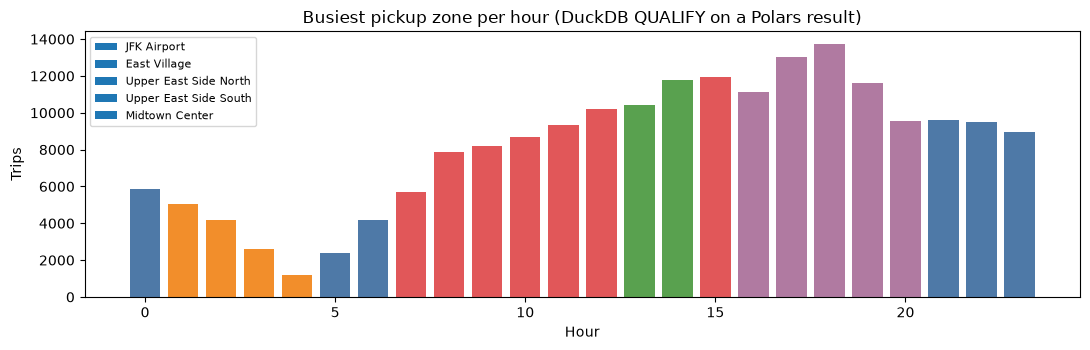

In [4]:
trips_pl = pl.read_parquet(JAN).filter(pl.col("fare_amount").is_between(3, 500))
hourly = con.sql("""
    SELECT PULocationID, extract(hour FROM tpep_pickup_datetime) AS hour, count(*) AS trips
    FROM trips_pl GROUP BY ALL
""").pl()                                                            # SQL on a Polars frame -> Polars result

busiest = con.sql("""
    SELECT z.Zone, h.hour, h.trips
    FROM hourly h JOIN zones_pd z ON z.LocationID = h.PULocationID
    QUALIFY row_number() OVER (PARTITION BY h.hour ORDER BY h.trips DESC) = 1      -- the busiest zone in each hour
    ORDER BY h.hour
""").df()
print(busiest["Zone"].value_counts().to_dict())

fig, ax = plt.subplots(figsize=(11, 3.6))
colors = {z: c for z, c in zip(busiest["Zone"].unique(), ["#4E79A7", "#F28E2B", "#E15759", "#59A14F", "#B07AA1", "#76B7B2"])}
ax.bar(busiest["hour"], busiest["trips"], color=[colors[z] for z in busiest["Zone"]])
for z, c in colors.items():
    ax.bar([], [], color=c, label=z)
ax.set(title="Busiest pickup zone per hour (DuckDB QUALIFY on a Polars result)", xlabel="Hour", ylabel="Trips")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

`QUALIFY` filters on a window function directly, a DuckDB (and Snowflake/BigQuery) extension that saves a subquery.

## 4. The Relational API

Instead of SQL strings, the **relational API** builds queries with Python methods. Each method returns a new lazy relation.

In [5]:
rel = (con.read_parquet(str(JAN))
       .filter("fare_amount BETWEEN 3 AND 500 AND payment_type = 1")
       .aggregate("PULocationID, avg(100 * tip_amount / fare_amount) AS tip_pct, count(*) AS n", "PULocationID")
       .filter("n >= 5000")
       .order("tip_pct DESC")
       .limit(5))
print(rel.sql_query()[:160], "...")
rel.df().merge(zones_pd, left_on="PULocationID", right_on="LocationID")[["Zone", "tip_pct", "n"]].round(1)

SELECT * FROM (SELECT * FROM (SELECT PULocationID, avg(((100 * tip_amount) / fare_amount)) AS tip_pct, count_star() AS n FROM (SELECT * FROM (SELECT * FROM parq ...


,Zone,tip_pct,n
0,Upper West Side South,27.3,70894
1,Upper East Side South,27.3,116268
2,Yorkville West,27.2,47117
3,Lincoln Square East,27.0,84289
4,Clinton East,26.8,57965


## 5. Benchmark: pandas, Polars, DuckDB

The same question in three engines: median fare and trip count per pickup zone and payment type, for January.

pandas (in memory)               151 ms
Polars (in memory)                95 ms
DuckDB on the pandas frame        46 ms
DuckDB on the Parquet file        96 ms


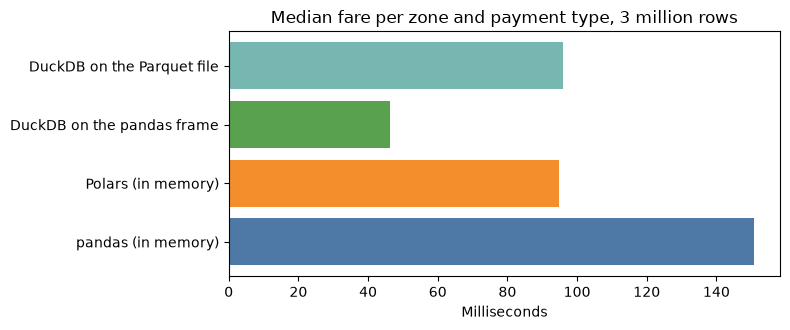

In [6]:
def best(fn, n=3):
    times = []
    for _ in range(n):
        t = time.perf_counter(); fn(); times.append(time.perf_counter() - t)
    return min(times) * 1000

trips_pl_all = pl.read_parquet(JAN)
timings = {
    "pandas (in memory)": best(lambda: trips_pd.groupby(["PULocationID", "payment_type"])["fare_amount"].agg(["median", "size"])),
    "Polars (in memory)": best(lambda: trips_pl_all.group_by("PULocationID", "payment_type").agg(
        pl.col("fare_amount").median(), pl.len())),
    "DuckDB on the pandas frame": best(lambda: con.sql(
        "SELECT PULocationID, payment_type, median(fare_amount), count(*) FROM trips_pd GROUP BY ALL").fetchall()),
    "DuckDB on the Parquet file": best(lambda: con.sql(
        f"SELECT PULocationID, payment_type, median(fare_amount), count(*) FROM '{JAN}' GROUP BY ALL").fetchall()),
}
for k, v in timings.items():
    print(f"{k:<28} {v:7.0f} ms")

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(list(timings), list(timings.values()), color=["#4E79A7", "#F28E2B", "#59A14F", "#76B7B2"])
ax.set(title="Median fare per zone and payment type, 3 million rows", xlabel="Milliseconds")
plt.tight_layout()
plt.show()

Polars and DuckDB both use all CPU cores and are usually much faster than pandas for this kind of aggregation; which one wins depends on the query and the data. DuckDB on the Parquet file also includes the time to read the file.

## 6. Choosing a Tool

| Situation | Good choice |
| :--- | :--- |
| exploring, plotting, libraries that expect pandas | pandas |
| fast DataFrame pipelines in Python code | Polars |
| SQL-heavy analysis, joins, window functions, files on disk | DuckDB |
| the team knows SQL better than DataFrame APIs | DuckDB |
| larger than memory | Polars streaming or DuckDB (both spill to disk) |

The three tools share Arrow, so you can combine them in one notebook without paying for conversions.

*Insight: You do not have to choose one tool. Keep data in Arrow-friendly formats (Parquet, Arrow tables) and use SQL with DuckDB, expressions with Polars, and pandas for the libraries that need it, each where it is clearest.*

## Real-World Use Case or Analogy

DuckDB on a DataFrame is like a **translator who reads your notes directly** instead of asking you to type them into a form first. You ask in SQL, and the answer comes back in whichever language (pandas, Polars, Arrow) you need next.

Analytics engineers prototype dbt models with DuckDB on local Parquet files (M11); data scientists answer join-heavy questions with SQL and continue in pandas for modelling; data apps embed DuckDB to query DataFrames on the fly.